# Echo benchmark: mpstab vs Pauli propagation

A circuit followed by its own inverse does nothing, so every expectation value at the end is known exactly. This notebook uses such an "echo" to measure how much error mpstab and [PauliPropagation.jl](https://github.com/MSRudolph/PauliPropagation.jl) accumulate, and how long they take, as the circuit gets deeper.

## Setup

The helpers in `frameworks.py`, next to this notebook, wrap both simulators behind the same interface. PauliPropagation.jl runs through `juliacall`: the first run downloads Julia and the package, which takes a few minutes. Each Pauli propagation run happens in a separate Julia process, stopped if the propagation takes more than `TIMEOUT` seconds: a propagation whose number of terms blows up cannot be interrupted from Python. The reported time excludes Julia's start-up and compilation.

In [1]:
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import frameworks as fw
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

set_style()

N = 64                          # qubits
STEPS = [2, 4, 6, 8, 10, 12]    # Floquet steps of U
CHI = [64, 128]                 # mpstab bond-dimension caps
PP_THRESHOLDS = [1e-3, 1e-4, 1e-5]  # PauliPropagation min_abs_coeff
TIMEOUT = 120                   # seconds per Pauli propagation run

## The echo circuit

$U$ is a kicked Ising chain: Clifford $ZZ$ couplings and magic $R_X$/$R_Z$ kicks, repeated for a number of Floquet steps. The echo circuit is $U$ followed by $U^\dagger$, so $\langle Z_{n/2}\rangle = 1$ exactly, at any width and depth. Neither simulator can see this shortcut: mpstab carries its MPS through the entanglement of $U$ and back out, and Pauli propagation builds up the Pauli terms of $U$ and has to cancel them again.

In [2]:
observable = fw.local_z(N, (N // 2,))
for steps in (STEPS[0], STEPS[-1]):
    circuit = fw.echo_circuit(N, steps)
    magic = fw.run_mpstab(circuit, observable, max_bond=8)["magic"]
    print(f"{steps:2d} steps: {len(circuit.queue)} gates, {magic} of them magic")

 2 steps: 1268 gates, 512 of them magic


12 steps: 7608 gates, 3072 of them magic


## Running both simulators

For every depth we run mpstab with two bond-dimension caps $\chi$, and Pauli propagation with three truncation thresholds `min_abs_coeff` (Pauli terms with smaller coefficients are dropped). The error is $|\langle Z_{n/2}\rangle - 1|$. The cost of both grows with depth, so once a threshold times out, deeper circuits are skipped for it.

In [3]:
pauli_propagation = fw.IsolatedPP(timeout=TIMEOUT)
rows = []
for steps in STEPS:
    circuit = fw.echo_circuit(N, steps)
    for chi in CHI:
        r = fw.run_mpstab(circuit, observable, max_bond=chi)
        rows.append(dict(method=rf"mpstab $\chi$={chi}", steps=steps,
                         error=abs(r["value"] - 1), time=r["time"]))
    for threshold in PP_THRESHOLDS:
        # Julia is compiled on one Floquet step of the circuit before timing.
        row = pauli_propagation(circuit, observable, threshold, reference=1.0,
                                warmup_gates=len(circuit.queue) // (2 * steps))
        rows.append(dict(row, steps=steps))
results = pd.DataFrame(rows)

## Results

Errors on the left, wall-clock times on the right, and the same numbers in the table below (times in seconds). A cross marks the run that hit the timeout; deeper circuits were not attempted for that threshold. Errors at machine precision are drawn at $10^{-16}$.

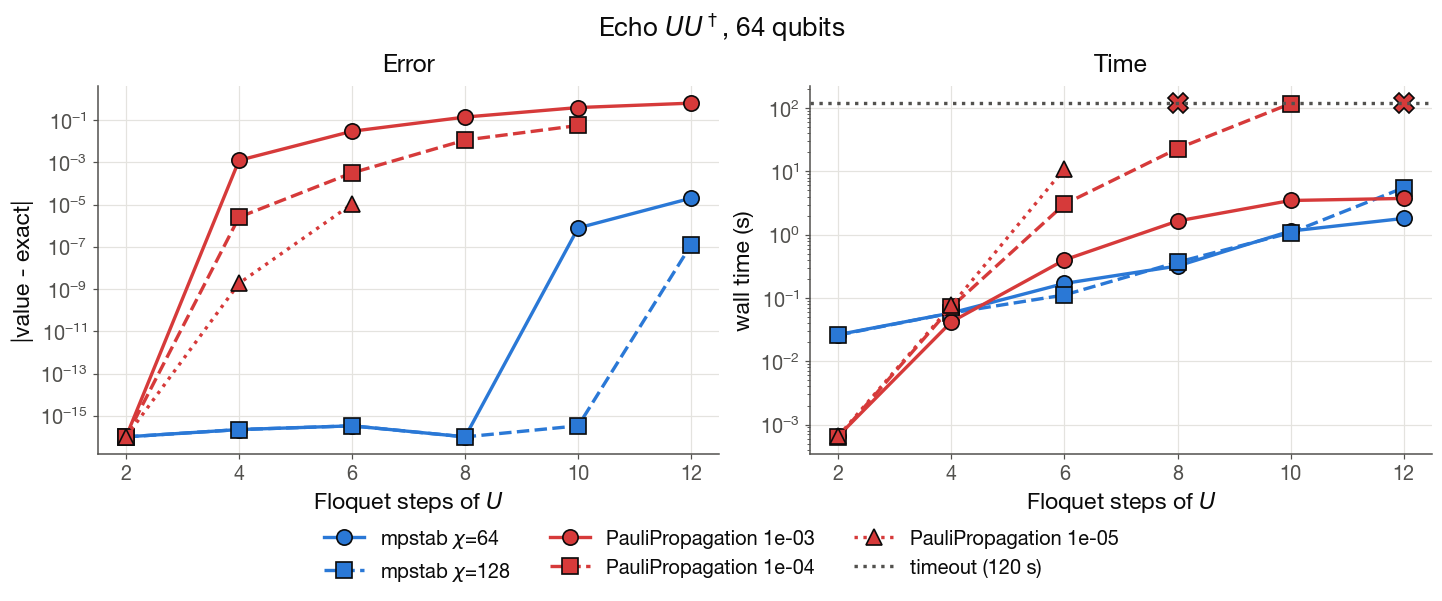

In [4]:
fw.plot_methods(results, "steps", "Floquet steps of $U$", title=rf"Echo $UU^\dagger$, {N} qubits",
                timeout=TIMEOUT)

In [5]:
table = results.pivot(index="steps", columns="method", values=["error", "time"])
table = table.reindex(columns=results.method.unique(), level=1)  # keep the plot's order
table.style.format("{:.1e}", subset="error", na_rep="-").format("{:.2f}", subset="time", na_rep="-")

Up to 8 steps mpstab is exact to machine precision with either cap: the bond dimension the echo needs stays below $\chi = 64$. Beyond that the cap starts to cut, and the error grows to about $10^{-5}$ for $\chi = 64$ and $10^{-7}$ for $\chi = 128$ at 12 steps, in 2 to 6 seconds.

Pauli propagation is exact and about 40 times faster than mpstab on the shallowest echo, where the light cone holds few Pauli strings. From 4 steps on, every threshold leaves an error well above mpstab's, and each tenfold tighter threshold costs several times more time: `1e-3` stays fast but is off by $0.64$ at 12 steps, `1e-4` is off by $10^{-2}$ after 23 s at 8 steps and by $6\times10^{-2}$ after almost 2 minutes at 10 steps, then times out, and `1e-5` times out already at 8 steps.

## Takeaways

- The echo is a hard test for both methods: the answer is trivial, but the circuit in between builds up as much entanglement, or as many Pauli strings, as a genuine deep circuit.
- For a couple of steps Pauli propagation is the fastest and exact.
- With depth, Pauli propagation must choose between a large truncation error and a runtime that explodes. mpstab stays exact up to 8 steps and keeps its error at or below $2\times10^{-5}$ up to 12 steps, in seconds.
- The bond-dimension cap $\chi$ is mpstab's accuracy knob: doubling it from 64 to 128 lowers the error at 12 steps by two orders of magnitude.